# DCGAN on MNIST: teaching a network to forge handwritten digits

**The question:** a **generative adversarial network (GAN)** trains two networks against each other: a *generator* that forges images from random noise and a *discriminator* that tries to spot the forgeries. The **DCGAN** recipe made this work with convolutional networks and a handful of settings. It can print an impressive grid of digits, but "looks good" is not a measurement. *How close do the forged digits get to real ones, are all ten digits produced, how fragile is the recipe, and is the generator just copying its training set?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. The referee: a way to judge generated digits
4. Hypotheses and why we chose each test
5. The DCGAN
6. H1: how close do the forgeries get?
7. H2: are all ten digits produced?
8. H3: how fragile is the recipe?
9. H4: is the generator copying the training set?
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab GAN/dcgan/dcgan.ipynb`, or *Run All* in any Jupyter. MNIST (about 12 MB) downloads itself on the first run. It uses a GPU if present and takes about 30 minutes on one.

## 1. 💡 The simple analogy

Imagine a **forger and an art detective** playing a game.

- The **forger (generator)** starts by scribbling random blobs. Each round, the detective looks at a pile of **real** paintings and a pile of the forger's **fakes**, and says which is which.
- The **detective (discriminator)** gets better at spotting fakes. The forger, told *how* the detective was fooled or not, gets better at faking. Both improve by competing.
- **Success** is when the detective can no longer tell: the fakes look like the real paintings.
- But there are traps: the forger might learn to paint **only one convincing digit** (mode collapse), or might simply **photocopy** real paintings. And the game is delicate: if one player gets too strong too fast, the other stops learning.
- We need an **independent referee** to judge the forgeries, not the detective who trained alongside the forger.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the image size and the training budget keeps the notebook reproducible and avoids "magic numbers". With the seeds fixed (and the GPU set to deterministic mode), every run comes out the same each time. **We use 32 x 32 images** (MNIST digits padded out from 28 pixels), where the legacy scripts used 64 x 64: the smaller size is about ten times cheaper to train on one small GPU and loses nothing important for digits.

In [1]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy import stats
from torch import nn
from torchvision import datasets

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
IMAGE_SIZE = 32  # MNIST digits are padded out from 28 to 32 pixels (the legacy scripts used 64)
Z_DIM = 100
N_EVAL = 10_000  # generated images used for the final scores
N_BOOTSTRAP = 2_000
BATCH = 128
STEPS = 4_000  # generator updates per training run (about 8.5 passes over MNIST)
TRACK_EVERY = 500
N_SEEDS = 3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. The referee: a way to judge generated digits

*What:* a GAN has no accuracy to report, so we build an **independent referee**: a small digit classifier trained only on real MNIST digits. It gives us three scores for any set of generated digits:

- **Fréchet distance (FD):** compare the *average and spread* of the referee's internal description of the generated digits with those of real test digits. Zero means identical; lower is better. It is the digit-sized cousin of the FID used for photographs.
- **Inception-style score:** high only if the referee is **sure** about each image *and* all ten digits appear (a perfect score is 10).
- **Confident share:** the share of images the referee is more than 90% sure about.

To know what "good" looks like, we first score **real digits against real digits** (10,000 training digits against the test digits): the floor no generator can beat.

In [2]:
def load_mnist() -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads MNIST as uint8 tensors (N, 28, 28) with labels, on the compute device.

    Returns:
        Training images and labels, then test images and labels.

    Raises:
        ValueError: If the dataset does not have the expected shape.
    """
    with contextlib.redirect_stderr(io.StringIO()):  # hide the download progress bars
        train = datasets.MNIST(DATA_DIR, train=True, download=True)
        test = datasets.MNIST(DATA_DIR, train=False, download=True)
    if tuple(train.data.shape) != (60_000, 28, 28) or tuple(test.data.shape) != (10_000, 28, 28):
        raise ValueError("Unexpected MNIST shape")
    return (
        train.data.to(DEVICE),
        train.targets.to(DEVICE),
        test.data.to(DEVICE),
        test.targets.to(DEVICE),
    )


def to_gan_scale(images: torch.Tensor) -> torch.Tensor:
    """Turns uint8 digits (N, 28, 28) into float images (N, 1, 32, 32) with values in [-1, 1]."""
    x = images.float().div(127.5).sub(1).unsqueeze(1)
    return F.interpolate(x, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)


def to_referee_scale(images: torch.Tensor) -> torch.Tensor:
    """Turns GAN-scale images (N, 1, 32, 32) back to (N, 1, 28, 28) in [0, 1] for the referee."""
    small = F.interpolate((images + 1) / 2, size=(28, 28), mode="area")
    return small.clamp(0, 1)


class Referee(nn.Module):
    """A small digit classifier (trained on real digits) used to judge generated images."""

    def __init__(self) -> None:
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
        )
        self.head = nn.Linear(128, 10)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """Returns class scores and the 128-number feature vector."""
        features = self.conv(x)
        return self.head(features), features


train_x, train_y, test_x, test_y = load_mnist()
torch.manual_seed(SEED)
referee = Referee().to(DEVICE)
optimizer = torch.optim.Adam(referee.parameters(), lr=1e-3)
for _ in range(3):
    order = torch.randperm(len(train_x), device=DEVICE)
    for start in range(0, len(order), 128):
        pick = order[start : start + 128]
        scores, _ = referee(train_x[pick].float().div(255).unsqueeze(1))
        loss = F.cross_entropy(scores, train_y[pick])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
referee.eval()


def referee_outputs(images01: torch.Tensor) -> tuple[np.ndarray, np.ndarray]:
    """Class probabilities and features for images in [0, 1] of shape (N, 1, 28, 28).

    Args:
        images01: Images scaled to [0, 1].

    Returns:
        Probabilities (N, 10) and features (N, 128) as NumPy arrays.
    """
    probs, feats = [], []
    with torch.no_grad():
        for start in range(0, len(images01), 2000):
            scores, f = referee(images01[start : start + 2000])
            probs.append(F.softmax(scores, dim=1).cpu().numpy())
            feats.append(f.cpu().numpy())
    return np.concatenate(probs), np.concatenate(feats).astype(np.float64)


test_probs, test_feats = referee_outputs(test_x.float().div(255).unsqueeze(1))
train_probs, train_feats = referee_outputs(train_x.float().div(255).unsqueeze(1))
REAL_MU, REAL_COV = test_feats.mean(0), np.cov(test_feats, rowvar=False)
real_share = np.bincount(test_y.cpu().numpy(), minlength=10) / len(test_y)
print(
    f"Referee accuracy on the real test digits: "
    f"{(test_probs.argmax(1) == test_y.cpu().numpy()).mean():.2%}"
)
print(
    f"Real digits per class in the test set: min {real_share.min():.1%}, max {real_share.max():.1%}"
)


def frechet_distance(
    feats: np.ndarray, mu_ref: np.ndarray = REAL_MU, cov_ref: np.ndarray = REAL_COV
) -> float:
    """Frechet distance between two clouds of referee features (lower = more alike).

    It compares the mean and spread of the features of some images with those of the real test
    digits; it is the digit-sized cousin of the FID used for photographs.

    Args:
        feats: Features of the images to judge, shape (N, 128).
        mu_ref: Mean of the reference features.
        cov_ref: Covariance of the reference features.

    Returns:
        The Frechet distance.
    """
    mu, cov = feats.mean(0), np.cov(feats, rowvar=False)
    # trace of the matrix square root of cov @ cov_ref = sum of square roots of its eigenvalues,
    # which are real and non-negative because both matrices are covariance matrices
    eigenvalues = np.linalg.eigvals(cov @ cov_ref).real.clip(min=0)
    return float(
        np.sum((mu - mu_ref) ** 2) + np.trace(cov + cov_ref) - 2 * np.sqrt(eigenvalues).sum()
    )


def inception_style_score(probs: np.ndarray) -> float:
    """exp(average KL divergence between each image's class guess and the overall class mix).

    High when every image is clearly one digit AND all ten digits appear. A perfect score is 10.

    Args:
        probs: Referee class probabilities, shape (N, 10).

    Returns:
        The score.
    """
    marginal = probs.mean(0, keepdims=True)
    kl = (probs * (np.log(probs + 1e-12) - np.log(marginal + 1e-12))).sum(1)
    return float(np.exp(kl.mean()))


@torch.no_grad()
def judge(generator: nn.Module, n: int = N_EVAL, seed: int = 0) -> dict:
    """Scores a generator: Frechet distance, Inception-style score, confidence and class mix.

    Args:
        generator: The generator to judge (it is run in training mode, so batch normalisation
            uses the statistics of each batch of 1,000 images, as when it was trained).
        n: Number of images to generate.
        seed: Seed for the random noise, so every generator sees the same noise.

    Returns:
        A dict with ``fd``, ``is``, ``confident`` (share of images the referee is more than 90%
        sure about), ``tvd`` (total variation distance of the class mix from the real one) and
        ``share`` (the class mix).
    """
    generator.train()
    gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
    images = torch.cat(
        [
            generator(torch.randn(1000, Z_DIM, 1, 1, device=DEVICE, generator=gen_cuda))
            for _ in range(n // 1000)
        ]
    )
    probs, feats = referee_outputs(to_referee_scale(images))
    share = np.bincount(probs.argmax(1), minlength=10) / len(probs)
    return {
        "fd": frechet_distance(feats),
        "is": inception_style_score(probs),
        "confident": float((probs.max(1) > 0.9).mean()),
        "tvd": float(0.5 * np.abs(share - real_share).sum()),
        "share": share,
    }


floor_rows = []
for i in range(5):
    sub = np.random.default_rng(i).choice(len(train_feats), N_EVAL, replace=False)
    floor_rows.append(
        {
            "fd": frechet_distance(train_feats[sub]),
            "is": inception_style_score(train_probs[sub]),
            "confident": float((train_probs[sub].max(1) > 0.9).mean()),
        }
    )
floor = pd.DataFrame(floor_rows)
print(
    f"Real digits judged the same way (10,000 real training digits against the real test "
    f"digits, 5 draws):\n  Frechet distance {floor['fd'].mean():.2f} "
    f"(range {floor['fd'].min():.2f} to {floor['fd'].max():.2f}), Inception-style score "
    f"{floor['is'].mean():.2f}, referee confident on {floor['confident'].mean():.1%}"
)

Referee accuracy on the real test digits: 98.92%
Real digits per class in the test set: min 8.9%, max 11.3%
Real digits judged the same way (10,000 real training digits against the real test digits, 5 draws):
  Frechet distance 1.89 (range 1.78 to 2.01), Inception-style score 9.59, referee confident on 96.6%


**How to read this:**

- **The referee is accurate:** it reads **98.92%** of the real test digits correctly.
- **The real-digit floor:** real training digits scored against the test digits give a Fréchet distance of **1.89** (range 1.78 to 2.01 over five draws), an Inception-style score of **9.59** (out of 10) and a referee that is confident on **96.6%** of images. A generator is judged against these numbers.
- **Real test digits are not perfectly balanced:** the commonest digit makes up **11.3%** and the rarest **8.9%**, so the generator's digit mix is compared with that, not with a flat 10%.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does the trained generator get close to real digits? | No better than an untrained generator | Much closer | Fréchet distance, Inception-style score and confident share, 3 seeds |
| H2 | Does it produce every digit in the right proportion? | Its digit mix matches the real mix | It does not | Total variation distance and a chi-square goodness-of-fit test against the real digit mix |
| H3 | Is the recipe robust to its settings? | Same quality at every setting | Differs | Adam momentum (0.5 vs 0.9) and learning rate (2e-4 vs 1e-3), 3 seeds each; Kruskal-Wallis and Mann-Whitney |
| H4 | Is the generator copying its training digits? | Generated digits are as far from the training set as unseen real ones | Closer (copying) | Distance to the nearest training digit; Mann-Whitney and Cliff's δ |

*Why these tests?* Fréchet distances are skewed and we only have three seeds per setting, so we use rank-based tests and report the individual runs. With 10,000 generated digits the chi-square test would flag even tiny differences, so for H2 we report the **total variation distance** (half the sum of the gaps between the two digit mixes) as the effect size.

## 5. The DCGAN

*What:* the DCGAN recipe, at 32 x 32.

- **Generator:** noise (100 numbers) → three transposed-convolution blocks with batch norm and ReLU → a 32 x 32 image with values in [-1, 1].
- **Discriminator:** three strided-convolution blocks with batch norm and LeakyReLU → one number squashed to 0 to 1.
- **Training:** the classic recipe: binary cross-entropy, **Adam with learning rate 0.0002 and momentum 0.5**, batches of 128, weights drawn from a narrow bell curve (N(0, 0.02)), **4,000 generator updates** (about 8.5 passes over MNIST). Every 500 updates we record the losses, the discriminator's average score on real and fake images and the Fréchet distance of 5,000 forged digits.

> **Problems in the legacy script this replaces:** it trained for 20 epochs at 64 x 64 and only wrote sample grids to TensorBoard, with **no measurement of quality at all**; no seed; it imported private PyTorch internals (`from torch._C import device`) and its comments mis-stated the discriminator's layer sizes (the model's shape test, `main()`, was commented out).

In [3]:
class Generator(nn.Module):
    """DCGAN generator: noise (N, 100, 1, 1) -> image (N, 1, 32, 32) with values in [-1, 1].

    Args:
        features: Width multiplier (the legacy scripts use 64).
    """

    def __init__(self, features: int = 64) -> None:
        super().__init__()

        def block(c_in: int, c_out: int, k: int, s: int, p: int) -> nn.Sequential:
            return nn.Sequential(
                nn.ConvTranspose2d(c_in, c_out, k, s, p, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
            )

        self.net = nn.Sequential(
            block(Z_DIM, features * 8, 4, 1, 0),  # 4 x 4
            block(features * 8, features * 4, 4, 2, 1),  # 8 x 8
            block(features * 4, features * 2, 4, 2, 1),  # 16 x 16
            nn.ConvTranspose2d(features * 2, 1, 4, 2, 1),  # 32 x 32
            nn.Tanh(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        """Turns noise into images."""
        return self.net(z)


def init_weights(model: nn.Module) -> None:
    """Draws every convolution and normalisation weight from N(0, 0.02), as the DCGAN paper does."""
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.BatchNorm2d)):
            nn.init.normal_(m.weight.data, 0.0, 0.02)

In [4]:
class Critic(nn.Module):
    """The discriminator / critic: image (N, 1, 32, 32) -> one score per image.

    Args:
        features: Width multiplier.
        norm: ``"batch"``, ``"instance"`` or ``"none"`` normalisation between layers.
        sigmoid: Squash the score to (0, 1), as a standard GAN discriminator does.
    """

    def __init__(self, features: int = 64, norm: str = "batch", sigmoid: bool = False) -> None:
        super().__init__()

        def make_norm(c: int) -> nn.Module:
            if norm == "batch":
                return nn.BatchNorm2d(c)
            if norm == "instance":
                return nn.InstanceNorm2d(c, affine=True)
            return nn.Identity()

        def block(c_in: int, c_out: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 4, 2, 1, bias=False), make_norm(c_out), nn.LeakyReLU(0.2)
            )

        layers: list[nn.Module] = [
            nn.Conv2d(1, features, 4, 2, 1),
            nn.LeakyReLU(0.2),  # 16 x 16
            block(features, features * 2),  # 8 x 8
            block(features * 2, features * 4),  # 4 x 4
            nn.Conv2d(features * 4, 1, 4, 1, 0),
        ]  # 1 x 1
        if sigmoid:
            layers.append(nn.Sigmoid())
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """One score per image."""
        return self.net(x).reshape(-1)

In [5]:
def real_batches(batch: int, seed: int):
    """Endless stream of random batches of real digits at GAN scale.

    Args:
        batch: Batch size.
        seed: Seed for the shuffling.

    Yields:
        Tensors of shape (batch, 1, 32, 32).
    """
    gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
    while True:
        order = torch.randperm(len(train_x), device=DEVICE, generator=gen_cuda)
        for start in range(0, len(order) - batch + 1, batch):
            yield to_gan_scale(train_x[order[start : start + batch]])


def show_grid(generator: nn.Module, ax: plt.Axes, seed: int = 123, n: int = 64) -> None:
    """Draws an 8 x 8 grid of generated digits on an axis.

    Args:
        generator: The generator.
        ax: The axis to draw on.
        seed: Seed for the noise.
        n: Number of images (a square number).
    """
    side = int(np.sqrt(n))
    with torch.no_grad():
        gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
        images = generator(torch.randn(n, Z_DIM, 1, 1, device=DEVICE, generator=gen_cuda))
    grid = images.cpu().numpy()[:, 0].reshape(side, side, IMAGE_SIZE, IMAGE_SIZE)
    ax.imshow(
        grid.transpose(0, 2, 1, 3).reshape(side * IMAGE_SIZE, side * IMAGE_SIZE),
        cmap="gray",
        vmin=-1,
        vmax=1,
    )
    ax.axis("off")

In [6]:
def train_dcgan(
    seed: int, steps: int = STEPS, lr: float = 2e-4, beta1: float = 0.5
) -> tuple[nn.Module, pd.DataFrame]:
    """Trains a DCGAN on MNIST with the classic recipe (binary cross-entropy, Adam).

    Every ``TRACK_EVERY`` steps it records the average losses, the discriminator's average score
    on real and on fake images, and the Frechet distance of 5,000 generated digits.

    Args:
        seed: Seed for the weights, batches and noise.
        steps: Number of generator updates.
        lr: Learning rate for both networks.
        beta1: Adam's first momentum coefficient (the DCGAN paper uses 0.5).

    Returns:
        The trained generator and a table with one row per checkpoint.
    """
    torch.manual_seed(seed)
    gen, disc = Generator().to(DEVICE), Critic(64, "batch", sigmoid=True).to(DEVICE)
    init_weights(gen)
    init_weights(disc)
    opt_gen = torch.optim.Adam(gen.parameters(), lr=lr, betas=(beta1, 0.999))
    opt_disc = torch.optim.Adam(disc.parameters(), lr=lr, betas=(beta1, 0.999))
    stream = real_batches(BATCH, seed)
    ones, zeros = torch.ones(BATCH, device=DEVICE), torch.zeros(BATCH, device=DEVICE)
    rows, window = [], []
    for step in range(1, steps + 1):
        real = next(stream)
        fake = gen(torch.randn(BATCH, Z_DIM, 1, 1, device=DEVICE))
        d_real, d_fake = disc(real), disc(fake.detach())
        loss_disc = (
            F.binary_cross_entropy(d_real, ones) + F.binary_cross_entropy(d_fake, zeros)
        ) / 2
        opt_disc.zero_grad()
        loss_disc.backward()
        opt_disc.step()
        loss_gen = F.binary_cross_entropy(disc(fake), ones)
        opt_gen.zero_grad()
        loss_gen.backward()
        opt_gen.step()
        window.append(
            (loss_disc.item(), loss_gen.item(), d_real.mean().item(), d_fake.mean().item())
        )
        if step % TRACK_EVERY == 0:
            mean = np.mean(window, axis=0)
            window = []
            rows.append(
                {
                    "step": step,
                    "loss_disc": mean[0],
                    "loss_gen": mean[1],
                    "d_real": mean[2],
                    "d_fake": mean[3],
                    "fd": judge(gen, 5_000, seed=1)["fd"],
                }
            )
    return gen, pd.DataFrame(rows)


untrained = Generator().to(DEVICE)
init_weights(untrained)
untrained_score = judge(untrained)
print(
    f"An untrained generator: Frechet distance {untrained_score['fd']:.1f}, Inception-style "
    f"score {untrained_score['is']:.2f}, referee confident on {untrained_score['confident']:.1%}"
)

An untrained generator: Frechet distance 1559.2, Inception-style score 1.00, referee confident on 0.0%


**How to read this:**

- **An untrained generator is as bad as can be:** Fréchet distance **1,559.2**, Inception-style score **1.00** (every image looks the same to the referee) and the referee is **0%** confident on its images. This is the "before" picture.

## 6. H1: how close do the forgeries get?

*What:* train the DCGAN with the classic recipe three times (seeds 0, 1 and 2) and judge 10,000 forged digits from each with the referee. We compare with the untrained generator (the worst case) and with real digits (the floor). The figure shows real digits, the forgeries of seed 0, and the Fréchet distance every 500 updates. *Why:* it tells us how much of the gap between "random noise" and "real digits" the training closes, and whether the three seeds agree.

In [7]:
recipe_runs = [train_dcgan(seed) for seed in range(N_SEEDS)]
recipe_scores = [judge(gen) for gen, _ in recipe_runs]
rows = [
    {"seed": i, **{k: v for k, v in s.items() if k != "share"}} for i, s in enumerate(recipe_scores)
]
final = pd.DataFrame(rows).set_index("seed")
print(f"DCGAN recipe, {STEPS:,} generator updates, {N_EVAL:,} generated digits per seed:")
print(final.round(3).to_string())
print(
    f"\nReference: untrained generator FD {untrained_score['fd']:.1f}; real digits "
    f"FD {floor['fd'].mean():.2f}, Inception-style score {floor['is'].mean():.2f}, "
    f"confident {floor['confident'].mean():.1%}"
)
share_of_gap = 1 - (final["fd"].mean() - floor["fd"].mean()) / (
    untrained_score["fd"] - floor["fd"].mean()
)
print(
    f"Share of the distance between an untrained generator and real digits that training "
    f"closes: {share_of_gap:.1%}"
)

DCGAN recipe, 4,000 generator updates, 10,000 generated digits per seed:
           fd     is  confident    tvd
seed                                  
0     157.737  6.771      0.599  0.042
1     170.976  6.705      0.601  0.058
2     159.859  6.654      0.592  0.073

Reference: untrained generator FD 1559.2; real digits FD 1.89, Inception-style score 9.59, confident 96.6%
Share of the distance between an untrained generator and real digits that training closes: 89.7%


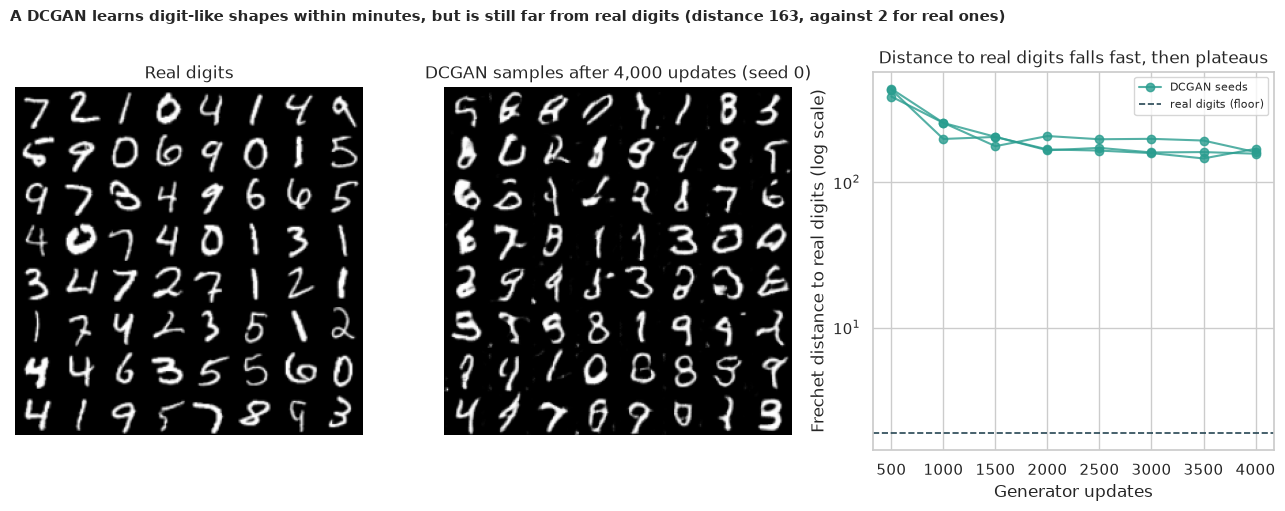

In [8]:
fig = plt.figure(figsize=(13, 5.2))
grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.15])
ax = fig.add_subplot(grid[0])
side = 8
real_imgs = (
    to_gan_scale(test_x[:64]).cpu().numpy()[:, 0].reshape(side, side, IMAGE_SIZE, IMAGE_SIZE)
)
ax.imshow(
    real_imgs.transpose(0, 2, 1, 3).reshape(side * IMAGE_SIZE, side * IMAGE_SIZE),
    cmap="gray",
    vmin=-1,
    vmax=1,
)
ax.axis("off")
ax.set_title("Real digits")
ax = fig.add_subplot(grid[1])
show_grid(recipe_runs[0][0], ax)
ax.set_title(f"DCGAN samples after {STEPS:,} updates (seed 0)")
ax = fig.add_subplot(grid[2])
for i, (_, history) in enumerate(recipe_runs):
    ax.plot(
        history["step"],
        history["fd"],
        marker="o",
        color=TEAL,
        alpha=0.8,
        label="DCGAN seeds" if i == 0 else None,
    )
ax.axhline(floor["fd"].mean(), color=NAVY, ls="--", lw=1.2, label="real digits (floor)")
ax.set_yscale("log")
ax.set_xlabel("Generator updates")
ax.set_ylabel("Frechet distance to real digits (log scale)")
ax.set_title("Distance to real digits falls fast, then plateaus")
ax.legend(fontsize=8)
fig.suptitle(
    f"A DCGAN learns digit-like shapes within minutes, but is still far from real "
    f"digits (distance {final['fd'].mean():.0f}, against {floor['fd'].mean():.0f} for "
    "real ones)",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_samples_and_progress.png", dpi=150)
plt.show()

**How to read this:**

- **Training closes most of the gap:** after 4,000 updates the Fréchet distance is **157.7, 171.0 and 159.9** for the three seeds (mean 162.9), down from **1,559.2** untrained, and **89.7%** of the way to the real-digit value of 1.89. **We reject H₀.** The curve falls fast in the first 1,000 updates and then flattens.
- **But the digits are still far from real ones:** the Inception-style score is **6.65 to 6.77** (real digits 9.59) and the referee is confident on only **59% to 60%** of the forged digits (real digits 96.6%). In the sample grid many digits are recognisable, but a good share are blurry or malformed.
- **The three seeds agree closely** (distances within 13 points of each other), so this is the recipe's typical result at this training length, not a lucky draw.
- The FD still sits about 85 times above the real-digit floor: longer training would lower it, and 4,000 updates is a short run.

## 7. H2: are all ten digits produced?

*What:* a GAN can "collapse" onto a few easy digits and ignore the rest. We read each of the 10,000 forged digits with the referee, count how often each digit appears, and compare with the real digit mix using the **total variation distance** (0 means identical mixes) and a chi-square goodness-of-fit test. *Why:* a generator that makes beautiful 1s and 7s only would score well on sharpness and fail on coverage.

In [9]:
mix = pd.DataFrame([s["share"] for s in recipe_scores], columns=[str(d) for d in range(10)])
print("Share of generated digits the referee reads as each class (per seed), against real digits:")
print((mix * 100).round(1).to_string())
print("real" + " " * 4 + "  ".join(f"{v * 100:4.1f}" for v in real_share))
for i, s in enumerate(recipe_scores):
    counts = np.round(s["share"] * N_EVAL)
    chi2, p = stats.chisquare(counts, f_exp=real_share * counts.sum())
    print(
        f"seed {i}: total variation distance from the real class mix {s['tvd']:.3f}; "
        f"chi-square(9) = {chi2:.0f}, p = {fmt_p(p)}; rarest digit {s['share'].min():.1%}, "
        f"commonest {s['share'].max():.1%}"
    )

Share of generated digits the referee reads as each class (per seed), against real digits:
      0     1     2     3    4    5    6     7     8     9
0  10.7  10.3  10.8  10.6  8.6  8.3  9.1  12.0   8.8  10.8
1  11.5  10.4  11.9  10.2  7.4  6.8  9.2  10.9   9.7  11.9
2  12.9  10.1  10.4   9.4  6.5  8.2  8.4  12.0  10.0  12.2
real     9.8  11.3  10.3  10.1   9.8   8.9   9.6  10.3   9.7  10.1
seed 0: total variation distance from the real class mix 0.042; chi-square(9) = 84, p = 2.9e-14; rarest digit 8.3%, commonest 12.0%
seed 1: total variation distance from the real class mix 0.058; chi-square(9) = 208, p = 6.4e-40; rarest digit 6.8%, commonest 11.9%
seed 2: total variation distance from the real class mix 0.073; chi-square(9) = 325, p = 1.3e-64; rarest digit 6.5%, commonest 12.9%


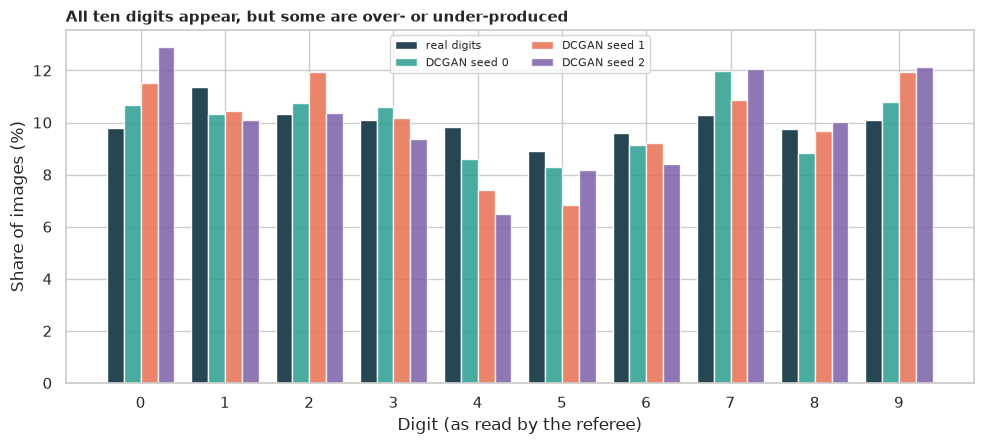

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.6))
width = 0.2
ax.bar(np.arange(10) - 1.5 * width, real_share * 100, width, color=NAVY, label="real digits")
for i, color in enumerate([TEAL, ORANGE, PURPLE]):
    ax.bar(
        np.arange(10) + (i - 0.5) * width,
        recipe_scores[i]["share"] * 100,
        width,
        color=color,
        alpha=0.85,
        label=f"DCGAN seed {i}",
    )
ax.set_xticks(range(10))
ax.set_xlabel("Digit (as read by the referee)")
ax.set_ylabel("Share of images (%)")
ax.set_title(
    "All ten digits appear, but some are over- or under-produced",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_class_mix.png", dpi=150)
plt.show()

**How to read this:**

- **No collapse: every digit appears in every seed.** The rarest digit makes up **6.5% to 8.3%** of the forged images and the commonest **11.9% to 12.9%**, against **8.9% to 11.3%** for real digits.
- **The mix is not perfect:** the total variation distance from the real digit mix is **0.042, 0.058 and 0.073**. The chi-square tests are all very significant (p from 3e-14 to 1e-64), but with 10,000 images any gap is, so the effect size is what matters: roughly 4% to 7% of the forgeries are "in the wrong digit".
- **The imbalance has a pattern:** across seeds, **4s and 5s are under-produced** (6.5% to 8.6% against 9.8% and 8.9% for real) while **0s, 7s and 9s are over-produced** (up to 12.9%). We **reject H₀** in the sense that the mix differs, but only mildly.

## 8. H3: how fragile is the recipe?

*What:* the DCGAN paper's settings look arbitrary: the Adam momentum of **0.5** (the usual default is 0.9) and the learning rate of **0.0002**. We vary them one at a time, with three seeds each: **momentum 0.9**, and a **learning rate five times larger (0.001)**, and compare the Fréchet distance with the classic recipe using a Kruskal-Wallis test and one-sided Mann-Whitney tests. *Why:* if the recipe only works at one precise setting, it is fragile.

In [11]:
VARIANTS = {
    "classic recipe (lr 2e-4, beta1 0.5)": (2e-4, 0.5),
    "beta1 = 0.9": (2e-4, 0.9),
    "lr 1e-3 (5 times larger)": (1e-3, 0.5),
}
variant_rows = []
for name, (lr, beta1) in VARIANTS.items():
    for seed in range(N_SEEDS):
        if name.startswith("classic"):
            score = recipe_scores[seed]
        else:
            gen, _ = train_dcgan(seed, lr=lr, beta1=beta1)
            score = judge(gen)
        variant_rows.append(
            {
                "variant": name,
                "seed": seed,
                "fd": score["fd"],
                "is": score["is"],
                "confident": score["confident"],
                "tvd": score["tvd"],
            }
        )
variants = pd.DataFrame(variant_rows)
print(
    variants.groupby("variant", sort=False)[["fd", "is", "confident", "tvd"]]
    .agg(["mean", "min", "max"])
    .round(2)
    .to_string()
)
groups = [g["fd"].to_numpy() for _, g in variants.groupby("variant", sort=False)]
kw = stats.kruskal(*groups)
print(
    f"\nKruskal-Wallis on the Frechet distance across the three variants: H = {kw.statistic:.1f}"
    f", p = {kw.pvalue:.3f}"
)
base = groups[0]
for name, g in list(zip(VARIANTS, groups, strict=True))[1:]:
    mw = stats.mannwhitneyu(g, base, alternative="greater")
    print(
        f"  {name} vs classic: FD {g.mean():.1f} vs {base.mean():.1f}; worse than every classic "
        f"run: {bool(g.min() > base.max())}; one-sided Mann-Whitney p = {mw.pvalue:.3f}"
    )

                                         fd                    is             confident               tvd            
                                       mean     min     max  mean   min   max      mean   min   max  mean   min   max
variant                                                                                                              
classic recipe (lr 2e-4, beta1 0.5)  162.86  157.74  170.98  6.71  6.65  6.77      0.60  0.59  0.60  0.06  0.04  0.07
beta1 = 0.9                          260.08  249.22  274.66  5.37  5.22  5.50      0.44  0.42  0.48  0.16  0.14  0.18
lr 1e-3 (5 times larger)             160.72  145.56  172.92  6.82  6.72  6.88      0.62  0.62  0.62  0.06  0.04  0.10

Kruskal-Wallis on the Frechet distance across the three variants: H = 5.4, p = 0.066
  beta1 = 0.9 vs classic: FD 260.1 vs 162.9; worse than every classic run: True; one-sided Mann-Whitney p = 0.050
  lr 1e-3 (5 times larger) vs classic: FD 160.7 vs 162.9; worse than every classic run: Fals

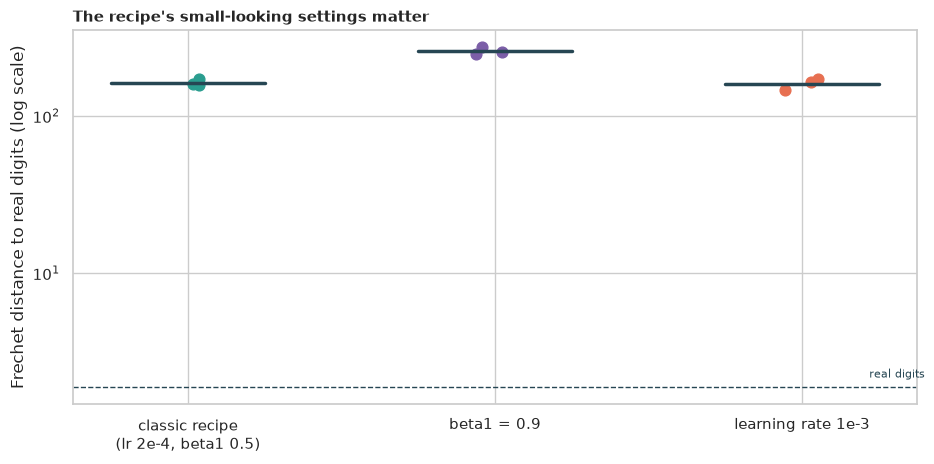

In [12]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for i, (name, color) in enumerate(zip(VARIANTS, [TEAL, PURPLE, ORANGE], strict=True)):
    sub = variants[variants["variant"] == name]["fd"]
    ax.scatter(np.full(len(sub), i) + rng.uniform(-0.07, 0.07, len(sub)), sub, color=color, s=60)
    ax.plot([i - 0.25, i + 0.25], [sub.mean()] * 2, color=NAVY, lw=2.5)
ax.axhline(floor["fd"].mean(), color=NAVY, ls="--", lw=1)
ax.text(2.4, floor["fd"].mean() * 1.15, "real digits", fontsize=8, ha="right", color=NAVY)
ax.set_yscale("log")
ax.set_xticks(
    range(3), ["classic recipe\n(lr 2e-4, beta1 0.5)", "beta1 = 0.9", "learning rate 1e-3"]
)
ax.set_ylabel("Frechet distance to real digits (log scale)")
ax.set_title(
    "The recipe's small-looking settings matter", loc="left", fontweight="bold", fontsize=11
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_recipe_sensitivity.png", dpi=150)
plt.show()

**How to read this:**

- **Momentum 0.9 hurts:** the Fréchet distance is **260.1** (runs from **249.2 to 274.7**) against **162.9** for the classic recipe (**157.7 to 171.0**): worse than **every** classic run. The Inception-style score falls from **6.71 to 5.37** and the referee's confident share from **60% to 44%**. The one-sided Mann-Whitney p is **0.050**, which is the smallest value 3 against 3 runs can give, and the Kruskal-Wallis p over the three settings is 0.066.
- **A five-times-larger learning rate makes no clear difference:** **160.7** (145.6 to 172.9) against **162.9** (p = 0.50 in the "worse" direction). So the learning rate has some slack, while the momentum does not.
- **The digit mix suffers too with momentum 0.9:** the total variation distance from the real mix rises from **0.06** to **0.16**.
- **Read with care:** three runs per setting cannot support a strong claim; the clear message is the *size* of the momentum effect (about 100 points of distance, about 60%), and that it appeared in all three runs.

## 9. H4: is the generator copying the training set?

*What:* a generator can "memorise": output training digits (or near copies) instead of new ones. For 2,000 forged digits from seed 0 and 2,000 **real unseen test digits**, we measure the pixel-space distance to the **nearest training digit**. If the generator copies, its digits will be unusually close to training digits, closer than unseen real digits are. We compare the two with a Mann-Whitney test and Cliff's δ, and count the forged digits that are closer to a training digit than 99% of unseen real digits are. *Why:* a high score from a copying generator would be meaningless.

In [13]:
N_PROBE = 2_000
gen0 = recipe_runs[0][0]
gen0.train()
with torch.no_grad():
    gen_cuda = torch.Generator(device=DEVICE).manual_seed(7)
    made = torch.cat(
        [
            gen0(torch.randn(1000, Z_DIM, 1, 1, device=DEVICE, generator=gen_cuda))
            for _ in range(N_PROBE // 1000)
        ]
    )
    made28 = to_referee_scale(made).flatten(1)
    train28 = train_x.float().div(255).flatten(1)
    held28 = test_x[:N_PROBE].float().div(255).flatten(1)
    nearest_made = (
        torch.cat(
            [
                torch.cdist(made28[i : i + 500], train28).min(1).values
                for i in range(0, N_PROBE, 500)
            ]
        )
        .cpu()
        .numpy()
    )
    nearest_held = (
        torch.cat(
            [
                torch.cdist(held28[i : i + 500], train28).min(1).values
                for i in range(0, N_PROBE, 500)
            ]
        )
        .cpu()
        .numpy()
    )
mw = stats.mannwhitneyu(nearest_made, nearest_held)
cliff = 2 * mw.statistic / (N_PROBE * N_PROBE) - 1
cutoff = np.percentile(nearest_held, 1)
print(f"Distance from a digit to its nearest training digit (pixel space, {N_PROBE:,} of each):")
print(
    f"  generated digits: median {np.median(nearest_made):.2f} "
    f"(5th to 95th percentile {np.percentile(nearest_made, 5):.2f} to "
    f"{np.percentile(nearest_made, 95):.2f})"
)
print(
    f"  real unseen (test) digits: median {np.median(nearest_held):.2f} "
    f"({np.percentile(nearest_held, 5):.2f} to {np.percentile(nearest_held, 95):.2f})"
)
print(
    f"Mann-Whitney p = {fmt_p(mw.pvalue)}, Cliff's delta = {cliff:+.2f} "
    "(positive: generated digits are farther from the training set)"
)
print(
    f"Generated digits closer to a training digit than 99% of unseen real digits are: "
    f"{(nearest_made < cutoff).mean():.1%} (a copying generator would be far above 1%)"
)

Distance from a digit to its nearest training digit (pixel space, 2,000 of each):
  generated digits: median 4.86 (5th to 95th percentile 3.09 to 6.25)
  real unseen (test) digits: median 4.40 (1.62 to 6.10)
Mann-Whitney p = 0.0e+00, Cliff's delta = +0.26 (positive: generated digits are farther from the training set)
Generated digits closer to a training digit than 99% of unseen real digits are: 0.0% (a copying generator would be far above 1%)


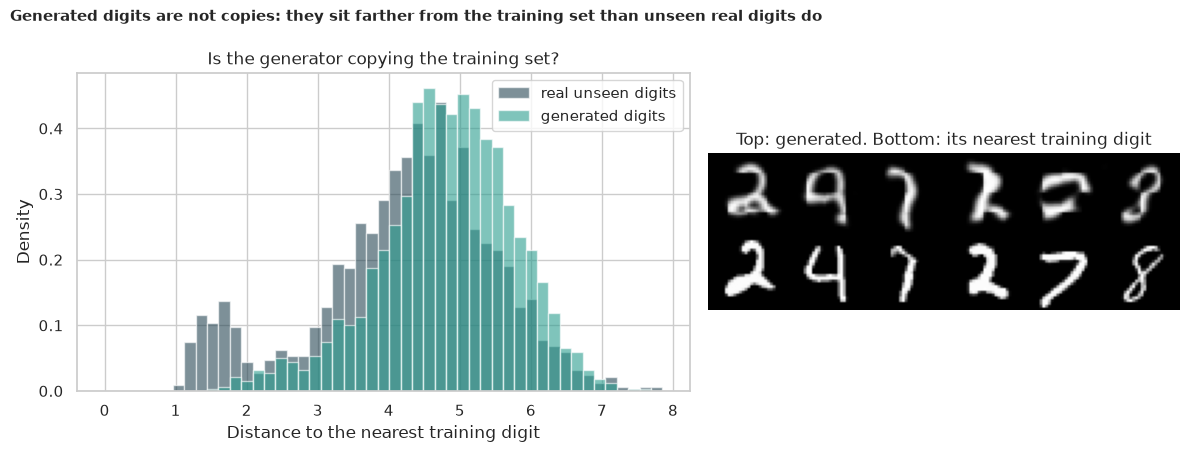

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
bins = np.linspace(0, max(nearest_made.max(), nearest_held.max()), 50)
axes[0].hist(
    nearest_held, bins=bins, color=NAVY, alpha=0.6, density=True, label="real unseen digits"
)
axes[0].hist(nearest_made, bins=bins, color=TEAL, alpha=0.6, density=True, label="generated digits")
axes[0].set_xlabel("Distance to the nearest training digit")
axes[0].set_ylabel("Density")
axes[0].set_title("Is the generator copying the training set?")
axes[0].legend()
nearest_idx = torch.cdist(made28[:6], train28).argmin(1)
tile = (
    torch.cat(
        [
            torch.cat([made28[i].view(28, 28), train28[nearest_idx[i]].view(28, 28)])
            for i in range(6)
        ],
        dim=1,
    )
    .cpu()
    .numpy()
)
axes[1].imshow(tile, cmap="gray")
axes[1].axis("off")
axes[1].set_title("Top: generated. Bottom: its nearest training digit")
fig.suptitle(
    "Generated digits are not copies: they sit farther from the training set than "
    "unseen real digits do",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_memorisation.png", dpi=150)
plt.show()

**How to read this:**

- **The generator is not copying:** the forged digits' median distance to the nearest training digit is **4.86** (5th to 95th percentile 3.09 to 6.25), against **4.40** (1.62 to 6.10) for real unseen digits. Cliff's δ is **+0.26** (the forgeries are *farther* from the training set), with p underflowing to 0. **We fail to find copying** (H₀ is not rejected in the direction of memorisation).
- **No forged digit is a near-copy:** **0.0%** of the 2,000 are closer to a training digit than 99% of unseen real digits are (a copying generator would be far above 1%).
- **A telling detail:** real unseen digits have a bump at distances of about 1.5, because many handwritten digits are near-duplicates of others. The forgeries have **no such bump**, which fits with their being blurrier, "average" digits rather than sharp copies of particular ones.
- In the side-by-side tiles, each forgery and its nearest training digit are often different digits entirely.

## 10. 🎯 Takeaways

1. **A DCGAN learns digit-like shapes in minutes:** the Fréchet distance to real digits falls from 1,559 to about 163 (89.7% of the way to the real-digit value of 1.9), consistently across three seeds.
2. **But "looks like digits" is far from "is like real digits":** the referee is confident on only about 60% of the forgeries (96.6% for real digits) and the Inception-style score is 6.7 against 9.6.
3. **There is no mode collapse here:** every digit appears, though the mix is off by 4% to 7% (total variation distance 0.04 to 0.07), with 4s and 5s under-produced.
4. **Adam's momentum matters:** 0.9 instead of 0.5 raises the Fréchet distance from 162.9 to 260.1 in every run; a five-times-larger learning rate does not.
5. **The generator is not copying:** its digits sit farther from the training set than unseen real digits do (Cliff's δ = +0.26), and none is a near-copy.
6. **Always judge a GAN with an independent measure,** not the loss the discriminator reports, and not a grid of hand-picked samples.

## 11. ⚠️ Limitations

- **The referee is a judge we built.** Its features come from a small classifier, so the Fréchet distance measures similarity *as the referee sees digits*. It is not comparable with published FID values for photographs.
- **A short training run** (4,000 updates, 8.5 passes over the data) and **three seeds per setting**, so p-values sit at their minimum possible value and the sensitivity result needs more runs to be firm.
- **32 x 32 digits, not 64 x 64** as in the legacy scripts; the architecture is a shortened DCGAN.
- **One-at-a-time settings.** We changed the momentum and learning rate separately, not together, and did not test other settings (batch size, normalisation, initialisation).
- **Pixel distance is a crude measure of copying.** A generator could be reusing strokes or parts of digits without being close in pixel space.
- **No human judgement:** the forged digits were never rated by people.